# Liu et al. (2025) DARM: Panasonic 25°C → 0°C

This notebook runs the manifest-controlled experiment. Target Cycle 1 is unlabelled during adaptation; target SOC is used only for final evaluation.

Start with `RUN_MODE = "smoke"`. Switch to `"formal"` only after the manifest and GPU checks pass.

In [3]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [4]:
from pathlib import Path

REPO_URL = "https://github.com/zhangcastle/battery-soc-transfer-benchmark.git"
REPO_ROOT = Path("/content/battery-soc-transfer-benchmark")
DATA_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF")
OUTPUT_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c")
RUN_MODE = "smoke"  # "smoke" or "formal"
SEED = 42

assert RUN_MODE in {"smoke", "formal"}


In [5]:
import shutil
import subprocess
import sys

from google.colab import drive, userdata

drive.mount("/content/drive")

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN is unavailable"

subprocess.run(
    ["gh", "auth", "login", "--hostname", "github.com", "--with-token"],
    input=token,
    text=True,
    check=True,
)
subprocess.run(["gh", "auth", "setup-git"], check=True)

# Remove a partial directory left by the failed clone.
if REPO_ROOT.exists() and not (REPO_ROOT / ".git").exists():
    shutil.rmtree(REPO_ROOT)

if (REPO_ROOT / ".git").exists():
    subprocess.run(
        ["git", "-C", str(REPO_ROOT), "pull", "--ff-only"],
        check=True,
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True,
    )

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_ROOT)],
    check=True,
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Repository: {REPO_ROOT}")
print(f"Data:       {DATA_ROOT}")
print(f"Outputs:    {OUTPUT_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository: /content/battery-soc-transfer-benchmark
Data:       /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF
Outputs:    /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c


In [6]:
import torch

assert torch.cuda.is_available(), "Select a Colab GPU runtime before training."
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name}")
print(f"VRAM: {gpu.total_memory / 2**30:.1f} GiB")
print("L4 memory is sufficient; formal-run duration is the main constraint.")


GPU: NVIDIA L4
VRAM: 22.0 GiB
L4 memory is sufficient; formal-run duration is the main constraint.


In [10]:
import subprocess
import sys

source_root = REPO_ROOT / "src"

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", str(REPO_ROOT)],
    check=True,
)

if str(source_root) not in sys.path:
    sys.path.insert(0, str(source_root))

import battery_benchmark

print(f"Package loaded from: {battery_benchmark.__file__}")

Package loaded from: /content/battery-soc-transfer-benchmark/src/battery_benchmark/__init__.py


In [11]:
import pandas as pd

from battery_benchmark.reproductions.liu_2025.protocol import load_experiment_manifest

MANIFEST = REPO_ROOT / "data/manifests/liu_2025/panasonic_25c_to_0c.csv"
manifest = load_experiment_manifest(MANIFEST, DATA_ROOT, verify_hashes=True)
display(manifest[["record_id", "temperature_c", "role", "profile", "label_usage"]])
display(manifest.groupby(["role", "label_usage"]).size().rename("files"))
assert manifest.loc[manifest.role == "target_adapt", "label_usage"].tolist() == ["forbidden"]


,record_id,temperature_c,role,profile,label_usage
0,source_train_cycle_1,25,source_train,Cycle_1,train
1,source_train_cycle_2,25,source_train,Cycle_2,train
2,source_train_cycle_3,25,source_train,Cycle_3,train
3,source_train_cycle_4,25,source_train,Cycle_4,train
4,source_test_la92,25,source_test,LA92,evaluation_only
5,source_test_udds,25,source_test,UDDS,evaluation_only
6,source_test_us06,25,source_test,US06,evaluation_only
7,source_test_hwfet_a,25,source_test,HWFET,evaluation_only
8,source_test_hwfet_b,25,source_test,HWFET,evaluation_only
9,source_test_nn,25,source_test,NN,evaluation_only


,,files
role,label_usage,
source_test,evaluation_only,6
source_train,train,4
target_adapt,forbidden,1
target_test,evaluation_only,5


In [7]:
script = REPO_ROOT / "scripts/reproductions/liu_2025/run_reproduction.py"
run_output = OUTPUT_ROOT / RUN_MODE
command = [
    sys.executable,
    str(script),
    "--manifest", str(MANIFEST),
    "--data-root", str(DATA_ROOT),
    "--output", str(run_output),
    "--device", "cuda",
    "--seed", str(SEED),
]
if RUN_MODE == "smoke":
    command += ["--smoke", "--max-windows", "2048"]
else:
    command += ["--resume"]

print(" ".join(command))
subprocess.run(command, cwd=REPO_ROOT, check=True)


NameError: name 'MANIFEST' is not defined

,method,profile,rmse_percent,mae_percent,n_windows
0,Source only,LA92,50.228413,45.029915,2048
1,Source only,UDDS,32.556145,27.578672,2048
2,Source only,US06,32.599190,27.878078,2048
3,Source only,HWFET,32.930370,28.016174,2048
4,Source only,NN,52.010273,47.214909,2048
5,DARM,LA92,35.510349,32.620819,2048
6,DARM,UDDS,31.438303,26.456577,2048
7,DARM,US06,33.489807,28.051805,2048
8,DARM,HWFET,32.657536,27.418163,2048
9,DARM,NN,36.190994,33.564873,2048


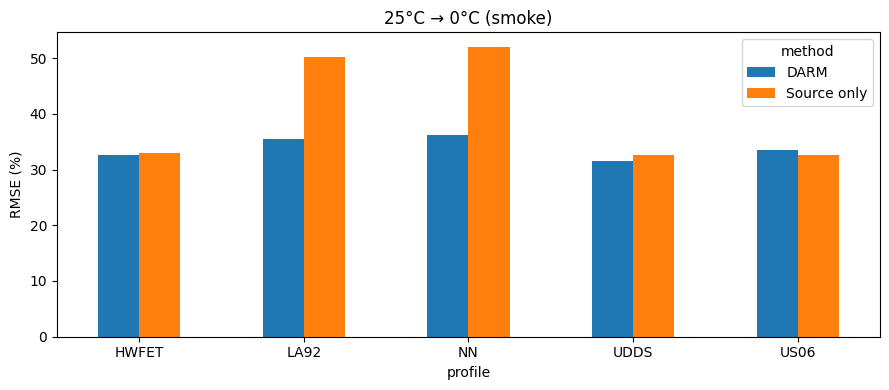

In [12]:
import json
import matplotlib.pyplot as plt

result = json.loads((run_output / "results.json").read_text())
rows = []
for method, key in [("Source only", "target_source_only"), ("DARM", "target_darm")]:
    for profile, metrics in result[key].items():
        rows.append({"method": method, "profile": profile, **metrics})
metrics = pd.DataFrame(rows)
display(metrics)
metrics.pivot(index="profile", columns="method", values="rmse_percent").plot.bar(
    ylabel="RMSE (%)", rot=0, figsize=(9, 4)
)
plt.title(f"25°C → 0°C ({RUN_MODE})")
plt.tight_layout()
plt.show()


## Adaptation diagnostic

This optional run reuses the frozen formal source artifact, keeps the source BatchNorm state frozen, and evaluates selected adaptation epochs. Target labels are used only for post-epoch diagnosis, never for optimization, early stopping, or checkpoint selection.

/usr/bin/python3 /content/battery-soc-transfer-benchmark/scripts/reproductions/liu_2025/run_reproduction.py --manifest /content/battery-soc-transfer-benchmark/data/manifests/liu_2025/panasonic_25c_to_0c.csv --data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --output /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/diagnostic_bn_frozen --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal/source_artifact.pt --device cuda --seed 42 --diagnose-adaptation --resume


,epoch,profile,rmse_percent,mae_percent,n_windows
0,0,LA92,6.271872,3.926723,15368
1,0,UDDS,6.077755,4.744146,12831
2,0,US06,12.152110,10.935865,3635
3,0,HWFET,10.421231,9.419899,5961
4,0,NN,6.049777,3.592366,13439
5,1,LA92,15.147264,9.466939,15368
6,1,UDDS,21.955494,18.539181,12831
7,1,US06,20.256168,17.429943,3635
8,1,HWFET,17.440292,13.892185,5961
9,1,NN,15.402166,8.986515,13439


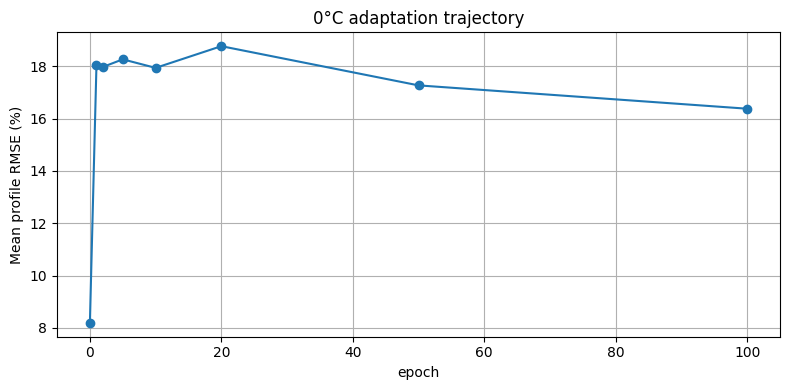

,min,max,outside_0_1_fraction
voltage,-0.021822,0.961565,0.065049
current,0.219858,0.647135,0.000000
temperature,-2.603329,-1.652916,1.000000


In [13]:
diagnostic_output = OUTPUT_ROOT / "diagnostic_bn_frozen"
source_artifact = OUTPUT_ROOT / "formal" / "source_artifact.pt"
assert source_artifact.is_file(), f"Missing source artifact: {source_artifact}"

diagnostic_command = [
    sys.executable,
    str(script),
    "--manifest", str(MANIFEST),
    "--data-root", str(DATA_ROOT),
    "--output", str(diagnostic_output),
    "--source-artifact", str(source_artifact),
    "--device", "cuda",
    "--seed", str(SEED),
    "--diagnose-adaptation",
    "--resume",
]
print(" ".join(diagnostic_command))
subprocess.run(diagnostic_command, cwd=REPO_ROOT, check=True)

diagnostic = json.loads((diagnostic_output / "results.json").read_text())
rows = [
    {"epoch": 0, "profile": profile, **values}
    for profile, values in diagnostic["target_source_only"].items()
]
for checkpoint in diagnostic["adaptation_diagnostics"]:
    rows.extend(
        {"epoch": checkpoint["epoch"], "profile": profile, **values}
        for profile, values in checkpoint["target_test"].items()
    )
trajectory = pd.DataFrame(rows)
display(trajectory)
trajectory.groupby("epoch")["rmse_percent"].mean().plot(
    marker="o", ylabel="Mean profile RMSE (%)", grid=True, figsize=(8, 4)
)
plt.title("0°C adaptation trajectory")
plt.tight_layout()
plt.show()

display(pd.DataFrame(diagnostic["normalized_feature_ranges"]["target_adapt"]).T)


## Interpretation

- Smoke metrics only prove that the complete real-data path runs; they are not comparable with the paper.
- Formal results are comparable only with the reconstruction assumptions recorded in `results.json`.
- `source_last.pt` and `adapt_last.pt` support resuming interrupted formal runs.
- Adaptation diagnostics use target labels only after selected epochs and never feed them into training or model selection.